# EnsembleMF ablation: does a per-drug standardized loss close the gap?

**Question.** `EnsembleMF` fits one squared error on raw ln IC50 across all drugs. Drugs differ widely in how much their response varies across cell lines, so the drugs with the widest spread dominate that loss. The models in `chocolate_challenge.ipynb` fit every drug on its own scale instead, and `EnsembleMF` falls furthest behind them on drugs with a narrow spread. Does the raw-scale loss cause part of the gap?

**Design.** `EnsembleMFStandardized` is DrEval's `EnsembleMF` with exactly the same settings and one change: before training, each drug's responses are centred and scaled to unit standard deviation with that drug's training statistics, and predictions are mapped back to ln IC50. Every drug then contributes to the loss on the same scale. It is run through DrEval on the 10 leaderboard splits and compared with the published `EnsembleMF` predictions, scored exactly as DrEval scores the leaderboard (normalized Pearson).

**Answer in short.** The loss weighting is real but explains little of the leaderboard gap. Drug by drug, standardization helps most on narrow-spread drugs and slightly hurts the widest ones. The leaderboard metric pools all test pairs and is dominated by the wide-spread drugs, so the overall score rises by only 0.006, about a fifth of the ridge's lead. In an unweighted ensemble with the ridge and the MLP it adds nothing.

| Section | |
|---|---|
| 1 | The model |
| 2 | Training on the leaderboard splits (cached) |
| 3 | Checking the scorer against DrEval |
| 4 | Overall result |
| 5 | Drug by drug |
| 6 | Why the per-drug gain barely moves the score |
| 7 | In the ensemble |

In [1]:
import inspect
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.stats import pearsonr, spearmanr, wilcoxon

warnings.filterwarnings("ignore")

from chocolate import EnsembleMFStandardized, plots
from chocolate import ensemble_mf_ablation as E

plots.style()
SPLITS = "reference/splits"
METRIC = "Pearson: normalized"
C = {"EnsembleMF": plots.BLUE, "EnsembleMFStandardized": plots.GREY, **plots.COLORS}

W1122 11:51:36.498000 18832 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


## 1. The model

`EnsembleMFStandardized` subclasses DrEval's `EnsembleMF` and changes only what goes into and comes out of it. The drug statistics come from the training pairs only; drugs never seen in training (none in LCO) would get the overall mean.

In [2]:
for name in ["train", "predict"]:
    print(inspect.getsource(getattr(EnsembleMFStandardized, name)))

    def train(
        self,
        output: DrugResponseDataset,
        cell_line_input: FeatureDataset,
        drug_input: FeatureDataset | None = None,
        output_earlystopping: DrugResponseDataset | None = None,
        model_checkpoint_dir: str = "checkpoints",
    ) -> None:
        """
        Fit per-drug statistics on the training responses, then train EnsembleMF on standardized targets.

        :param output: training responses
        :param cell_line_input: cell-line features
        :param drug_input: drug features
        :param output_earlystopping: early-stopping responses
        :param model_checkpoint_dir: unused
        """
        y = np.asarray(output.response, dtype=float)
        drugs = np.asarray(output.drug_ids)
        self.raw_mean = float(np.nanmean(y))
        self.drug_stats = {}
        for d in np.unique(drugs):
            v = y[drugs == d]
            sd = float(np.nanstd(v))
            self.drug_stats[d] = (float(np.nanmean(v)), sd if sd > 1

Its settings in `chocolate/hyperparameters.yaml` are a copy of DrEval's own `EnsembleMF` entry (20 ensemble members, rank-transformed landmark-gene expression, drug fingerprints plus a drug embedding):

In [3]:
from pathlib import Path

from drevalpy.models.EnsembleMF.ensemble_mf import EnsembleMF

dreval_settings = yaml.safe_load(open(Path(inspect.getfile(EnsembleMF)).parent / "hyperparameters.yaml"))["EnsembleMF"]
ours = yaml.safe_load(open("chocolate/hyperparameters.yaml"))["EnsembleMFStandardized"]
print("same settings as DrEval's EnsembleMF:", ours == dreval_settings)
pd.Series({k: v[0] for k, v in ours.items()}).to_frame("value").T

same settings as DrEval's EnsembleMF: True


,feature_transform,gene_list,n_bits,hidden_dim,emb_dim,n_layers,dropout,use_mlp_head,mlp_hidden,use_drug_id_embedding,n_ensemble,learning_rate,weight_decay,batch_size,max_epochs,patience,seed
value,rank,landmark_genes,256,256,128,1,0.2,True,256,True,20,0.0003,0.00001,2048,300,25,0


## 2. Training on the leaderboard splits

`E.run` trains the model on every split that has no stored predictions in `results/emf_standardized`. One split takes about 8 minutes on one GPU. The network is small enough that a single split leaves the GPU mostly idle, so three splits are trained at once in separate processes, which costs no extra time per split: about 30 minutes for all 10. If all 10 are stored, nothing is trained.

In [4]:
E.run(n_workers=3)
print("splits with predictions:", E.done_splits())

All 10 splits are stored in results\emf_standardized\CTRPv2\LCO; nothing to train.
splits with predictions: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 3. Checking the scorer against DrEval

To score averages of models, the predictions of every model are put side by side and scored here rather than by DrEval's report. The scorer reproduces DrEval's normalized Pearson exactly. One detail matters: DrEval's prediction files repeat a few pairs, and its normalization step merges two such files, so a pair repeated *c* times counts *c*² times. `E.score` weights the pairs the same way.

In [5]:
tables = [E.test_table(k) for k in range(10)]

official = pd.read_csv("results/final/evaluation_results.csv", index_col=0)
official = official[(official.rand_setting == "predictions") & (official.test_mode == "LCO")]
official = official.pivot(index="CV_split", columns="algorithm", values=METRIC)
leaderboard = pd.read_csv("reference/leaderboard_evaluation_results.csv")
leaderboard = leaderboard[leaderboard.rand_setting == "predictions"].pivot(index="CV_split", columns="algorithm", values=METRIC)

check = pd.DataFrame({
    "PerDrugRidge": [E.score(t, t.ridge) - official.PerDrugRidge[k] for k, t in enumerate(tables)],
    "MultiTaskMLP": [E.score(t, t.mlp) - official.MultiTaskMLP[k] for k, t in enumerate(tables)],
    "AverageEnsemble": [E.score(t, (t.ridge + t.mlp) / 2) - official.AverageEnsemble[k] for k, t in enumerate(tables)],
    "EnsembleMF (published)": [E.score(t, t.emf) - leaderboard.EnsembleMF[k] for k, t in enumerate(tables)],
})
print(f"largest difference from DrEval's official scores over 10 splits: {check.abs().max().max():.1e}")

largest difference from DrEval's official scores over 10 splits: 5.6e-16


## 4. Overall result

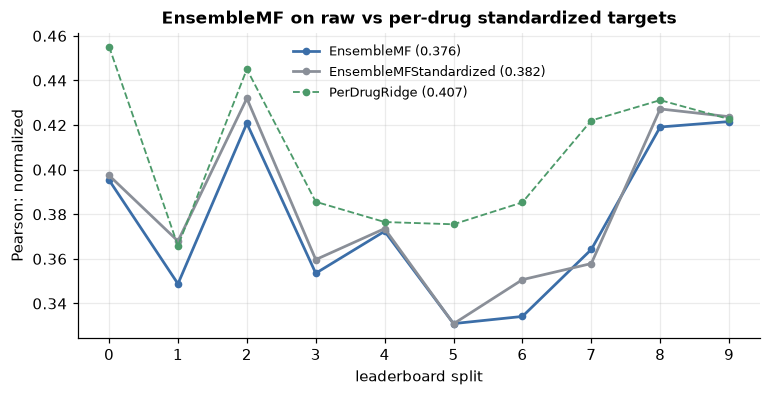

EnsembleMF (published)        0.3761
EnsembleMFStandardized        0.3821
gain                          +0.0060   ahead on 8 of 10 splits, Wilcoxon signed-rank p = 0.037
share of PerDrugRidge's lead (0.030) closed: 20%
share of AverageEnsemble's lead (0.047) closed: 13%


,EnsembleMF,EnsembleMFStandardized,PerDrugRidge,MultiTaskMLP,AverageEnsemble,gain
split,,,,,,
0,0.3953,0.3974,0.4552,0.3764,0.4449,0.0021
1,0.3488,0.3680,0.3659,0.3807,0.3858,0.0192
2,0.4208,0.4320,0.4451,0.4660,0.4710,0.0112
3,0.3536,0.3597,0.3856,0.3717,0.3926,0.0061
4,0.3724,0.3736,0.3765,0.4259,0.4155,0.0012
5,0.3310,0.3309,0.3755,0.3665,0.3845,-0.0001
6,0.3342,0.3507,0.3853,0.3901,0.4009,0.0165
7,0.3642,0.3579,0.4221,0.3924,0.4228,-0.0063
8,0.4191,0.4272,0.4312,0.4540,0.4629,0.0081


In [6]:
res = pd.DataFrame({
    "EnsembleMF": [E.score(t, t.emf) for t in tables],
    "EnsembleMFStandardized": [E.score(t, t.emf_std) for t in tables],
    "PerDrugRidge": [E.score(t, t.ridge) for t in tables],
    "MultiTaskMLP": [E.score(t, t.mlp) for t in tables],
    "AverageEnsemble": [E.score(t, (t.ridge + t.mlp) / 2) for t in tables],
}).rename_axis("split")
res["gain"] = res.EnsembleMFStandardized - res.EnsembleMF

x = np.arange(10)
fig, ax = plt.subplots(figsize=(8, 3.6))
for m in ["EnsembleMF", "EnsembleMFStandardized", "PerDrugRidge"]:
    style = "o--" if m == "PerDrugRidge" else "o-"
    ax.plot(x, res[m], style, color=C[m], lw=1.2 if m == "PerDrugRidge" else 1.8, ms=4, label=f"{m} ({res[m].mean():.3f})")
ax.set(title="EnsembleMF on raw vs per-drug standardized targets", xlabel="leaderboard split", ylabel=METRIC, xticks=x)
ax.legend(frameon=False, fontsize=8.5)
plt.show()

g = res.gain
print(f"EnsembleMF (published)        {res.EnsembleMF.mean():.4f}")
print(f"EnsembleMFStandardized        {res.EnsembleMFStandardized.mean():.4f}")
print(f"gain                          {g.mean():+.4f}   ahead on {(g > 0).sum()} of 10 splits, Wilcoxon signed-rank p = {wilcoxon(g).pvalue:.3f}")
for m in ["PerDrugRidge", "AverageEnsemble"]:
    gap = res[m].mean() - res.EnsembleMF.mean()
    print(f"share of {m}'s lead ({gap:.3f}) closed: {g.mean() / gap:.0%}")
res.round(4)

The gain is small but fairly consistent. Two caveats keep it modest. The 10 splits share most of their training data, so the p-value is optimistic. And retraining the original `EnsembleMF` moves single splits by up to about 0.01 from the published run (training is not deterministic on the GPU), which is as large as several of the per-split gains. Either way, standardization recovers only a small part of the lead of the models in `chocolate_challenge.ipynb`, and the standardized model stays well behind both of them.

## 5. Drug by drug

The hypothesis predicts more than a higher score: standardization should help most on the drugs that the raw-scale loss neglects, the ones with a narrow spread. For every drug with at least 10 test cell lines in a split, the table below takes the Pearson correlation of the normalized responses and predictions within that drug, averages it over the splits, and groups drugs into fifths by the spread (standard deviation) of their ln IC50 across the training cell lines.

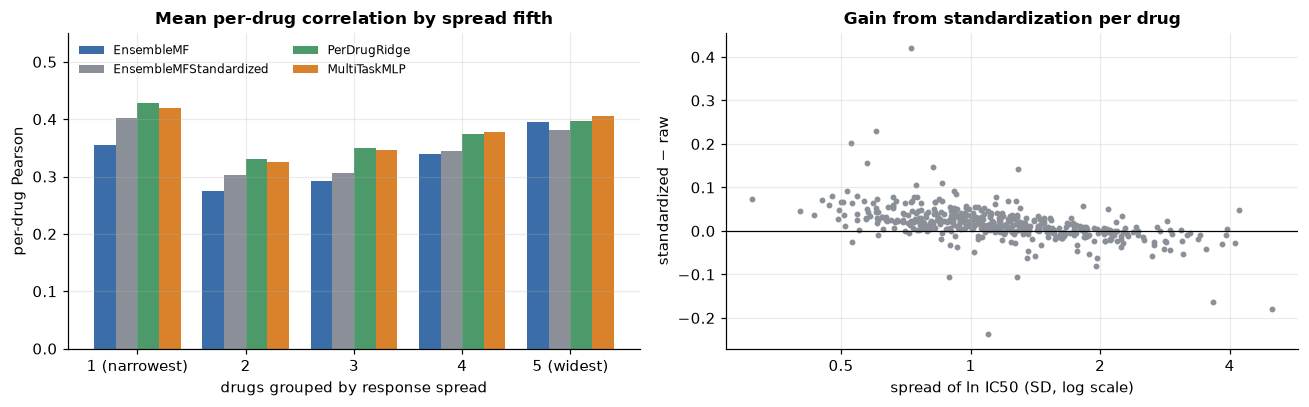

470 drugs; standardization helps 72% of them; Spearman(spread, gain) = -0.64 (p = 1e-55)


,spread,EnsembleMF,EnsembleMFStandardized,gain,PerDrugRidge,MultiTaskMLP
fifth,,,,,,
1 (narrowest),0.6461,0.3554,0.4017,0.0463,0.4286,0.4191
2,0.9102,0.2745,0.3022,0.0277,0.3302,0.3253
3,1.1447,0.2924,0.3068,0.0144,0.3503,0.3468
4,1.4902,0.3388,0.3441,0.0052,0.3738,0.3773
5 (widest),2.4060,0.3945,0.3820,-0.0125,0.3961,0.4054


In [7]:
rows = []
for k, t in enumerate(tables):
    spread = pd.read_csv(f"{SPLITS}/cv_split_{k}_train.csv", dtype={"pubchem_id": str}).groupby("pubchem_id").response.std()
    for drug, g_ in t.groupby("pubchem_id"):
        if len(g_) < 10:
            continue
        y = g_.response - g_.naive
        rows.append({"drug": drug, "spread": spread.get(drug, np.nan),
                     **{m: pearsonr(y, g_[col] - g_.naive)[0] for m, col in
                        [("EnsembleMF", "emf"), ("EnsembleMFStandardized", "emf_std"), ("PerDrugRidge", "ridge"), ("MultiTaskMLP", "mlp")]}})
per_drug = pd.DataFrame(rows).groupby("drug").mean().dropna()
per_drug["gain"] = per_drug.EnsembleMFStandardized - per_drug.EnsembleMF
per_drug["fifth"] = pd.qcut(per_drug.spread, 5, labels=["1 (narrowest)", "2", "3", "4", "5 (widest)"])
by_fifth = per_drug.groupby("fifth", observed=True)[["spread", "EnsembleMF", "EnsembleMFStandardized", "gain", "PerDrugRidge", "MultiTaskMLP"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.2
for i, m in enumerate(["EnsembleMF", "EnsembleMFStandardized", "PerDrugRidge", "MultiTaskMLP"]):
    axes[0].bar(np.arange(5) + (i - 1.5) * w, by_fifth[m], w, color=C[m], label=m)
axes[0].set(title="Mean per-drug correlation by spread fifth", xticks=range(5), xticklabels=by_fifth.index, xlabel="drugs grouped by response spread", ylabel="per-drug Pearson")
axes[0].set_ylim(0, 0.55)
axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
axes[1].scatter(per_drug.spread, per_drug.gain, s=8, color=plots.GREY)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xscale="log", title="Gain from standardization per drug", xlabel="spread of ln IC50 (SD, log scale)", ylabel="standardized − raw")
axes[1].set_xticks([0.5, 1, 2, 4], ["0.5", "1", "2", "4"])
axes[1].minorticks_off()
plt.tight_layout()
plt.show()

rho, p = spearmanr(per_drug.spread, per_drug.gain)
print(f"{len(per_drug)} drugs; standardization helps {(per_drug.gain > 0).mean():.0%} of them; Spearman(spread, gain) = {rho:.2f} (p = {p:.0e})")
by_fifth.round(4)

This is the pattern the hypothesis predicts, and now it comes from an intervention rather than a correlation. Standardization helps most on the narrowest-spread drugs and progressively less as the spread grows, until it slightly hurts the widest fifth: the loss no longer concentrates on those drugs. On the narrowest drugs it closes much of the per-drug gap to the ridge and the MLP, though not all of it.

## 6. Why the per-drug gain barely moves the score

If standardization helps most drugs, why does the leaderboard score rise by only 0.006? Because the leaderboard metric weights drugs much as the raw-scale loss does. DrEval computes one Pearson correlation over all test pairs of a split, pooled across drugs. A drug's share of that correlation grows with how much its normalized responses vary, so the wide-spread drugs dominate the score just as they dominate `EnsembleMF`'s loss. Standardization moves effort from the drugs that count most in the score to the ones that count least.

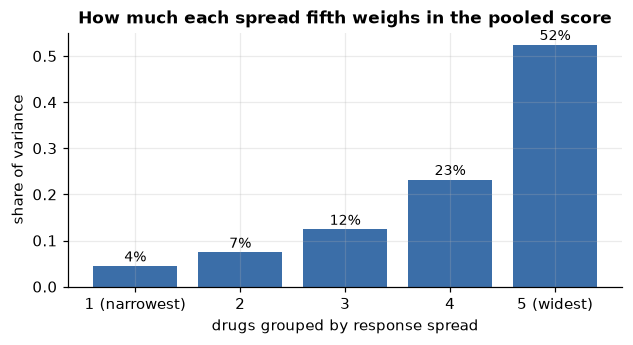

,share of the score's variance,per-drug gain
fifth,,
1 (narrowest),0.045,0.046
2,0.074,0.028
3,0.124,0.014
4,0.232,0.005
5 (widest),0.525,-0.013


In [8]:
share = []
for k, t in enumerate(tables):
    tt = t.merge(per_drug[["fifth"]], left_on="pubchem_id", right_index=True)
    y2 = (tt.c ** 2) * (tt.response - tt.naive) ** 2
    share.append(y2.groupby(tt.fifth, observed=True).sum() / y2.sum())
share = pd.concat(share, axis=1).mean(axis=1)
out = pd.DataFrame({"share of the score's variance": share, "per-drug gain": by_fifth.gain})
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(range(5), share, color=plots.BLUE)
for i, v in enumerate(share):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
ax.set(title="How much each spread fifth weighs in the pooled score", xticks=range(5), xticklabels=share.index, xlabel="drugs grouped by response spread", ylabel="share of variance")
plt.show()
out.round(3)

So the earlier objection holds for the leaderboard score: a loss that concentrates on wide-spread drugs is not badly matched to a metric that does the same. The loss weighting does make `EnsembleMF` worse on most individual drugs, but those drugs carry little weight in the score. Most of the leaderboard gap between `EnsembleMF` and the models here therefore has another cause, which this ablation does not identify.

## 7. In the ensemble

Does the standardized model help as a third member of the unweighted average? No: it is clearly weaker than the ridge and the MLP, and its errors overlap with the MLP's (normalized predictions correlate about 0.88), so an equal share pulls the average down slightly.

In [9]:
ens = pd.DataFrame({
    "ridge + MLP": [E.score(t, (t.ridge + t.mlp) / 2) for t in tables],
    "ridge + MLP + EnsembleMFStandardized": [E.score(t, (t.ridge + t.mlp + t.emf_std) / 3) for t in tables],
    "ridge + MLP + EnsembleMF": [E.score(t, (t.ridge + t.mlp + t.emf) / 3) for t in tables],
}).rename_axis("split")
d = ens.iloc[:, 1] - ens.iloc[:, 0]
print(f"adding EnsembleMFStandardized: {d.mean():+.4f} on average, ahead on {(d > 0).sum()} of 10 splits, Wilcoxon p = {wilcoxon(d).pvalue:.2f}")

def corr(a, b):
    return np.mean([np.corrcoef(t[a] - t.naive, t[b] - t.naive)[0, 1] for t in tables])

print(f"correlation of normalized predictions: ridge-MLP {corr('ridge', 'mlp'):.2f}, ridge-standardized {corr('ridge', 'emf_std'):.2f}, MLP-standardized {corr('mlp', 'emf_std'):.2f}")
pd.concat([ens, ens.mean().to_frame("mean").T]).round(4)

adding EnsembleMFStandardized: -0.0016 on average, ahead on 6 of 10 splits, Wilcoxon p = 0.77


correlation of normalized predictions: ridge-MLP 0.86, ridge-standardized 0.80, MLP-standardized 0.88


,ridge + MLP,ridge + MLP + EnsembleMFStandardized,ridge + MLP + EnsembleMF
0,0.4449,0.4474,0.4482
1,0.3858,0.3897,0.3856
2,0.4710,0.4721,0.4676
3,0.3926,0.3931,0.3931
4,0.4155,0.4133,0.4142
5,0.3845,0.3773,0.3782
6,0.4009,0.3928,0.3877
7,0.4228,0.4130,0.4148
8,0.4629,0.4631,0.4614
9,0.4494,0.4520,0.4533


## Summary

- Training `EnsembleMF` on per-drug standardized targets raises its leaderboard score from 0.376 to 0.382, ahead on 8 of 10 splits. That is about a fifth of the ridge's lead and an eighth of the ensemble's.
- Drug by drug the effect is much larger and follows the hypothesis: the narrower a drug's spread, the more standardization helps, and it slightly hurts the widest drugs.
- The pooled leaderboard metric is dominated by the wide-spread drugs, the same drugs the raw-scale loss favours, so the per-drug gains barely register in the score. Most of the gap to the models here remains unexplained.
- As a third member of the unweighted ensemble it adds nothing.